# STAT5291 Final Project  
## Full clustering analysis notebook for final report

This notebook is designed to support the **full final report**.

1. Data description  
2. Exploratory data analysis  
3. K-means results  
4. GMM results  
5. Spectral Clustering results
6. Hierarchical Clustering results
7. Final model comparison  
8. Export tables for reporting

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.stats import chi2_contingency

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

## 1. Load data

In [2]:
file_path = '/content/Mall_Customers.csv'
df = pd.read_csv(file_path)
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 2. Data description

This section gives the basic dataset structure and summary statistics.

In [3]:
print('Shape of dataset:', df.shape)
print('\nColumn names:')
print(df.columns.tolist())

Shape of dataset: (200, 5)

Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


In [4]:
numeric_features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
display(df[numeric_features].describe())

,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


In [5]:
print('Missing values by column:')
display(df.isnull().sum().to_frame('missing_count'))

Missing values by column:


,missing_count
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


## 3. Exploratory data analysis

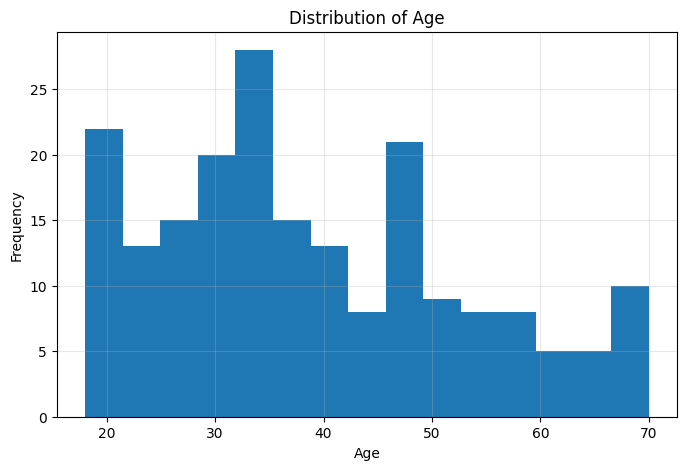

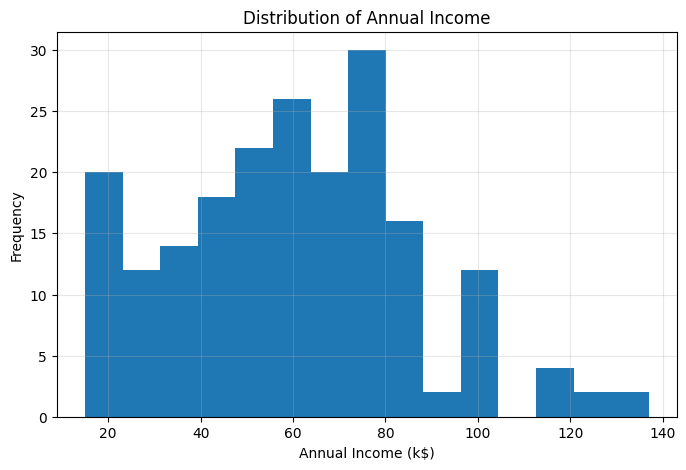

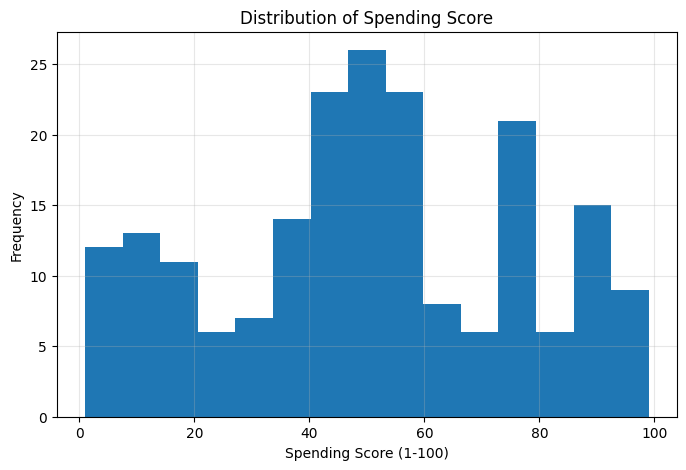

In [6]:
plt.figure(figsize=(8,5))
plt.hist(df['Age'], bins=15)
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Distribution of Age')
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(8,5))
plt.hist(df['Annual Income (k$)'], bins=15)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Frequency')
plt.title('Distribution of Annual Income')
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(8,5))
plt.hist(df['Spending Score (1-100)'], bins=15)
plt.xlabel('Spending Score (1-100)')
plt.ylabel('Frequency')
plt.title('Distribution of Spending Score')
plt.grid(alpha=0.3)
plt.show()

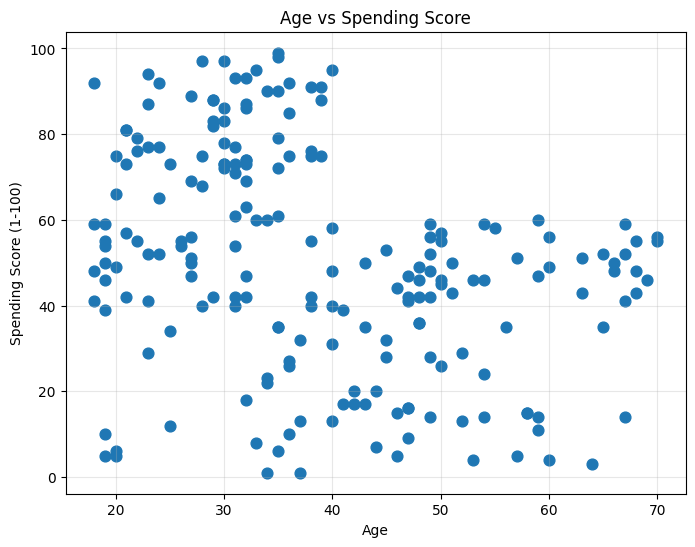

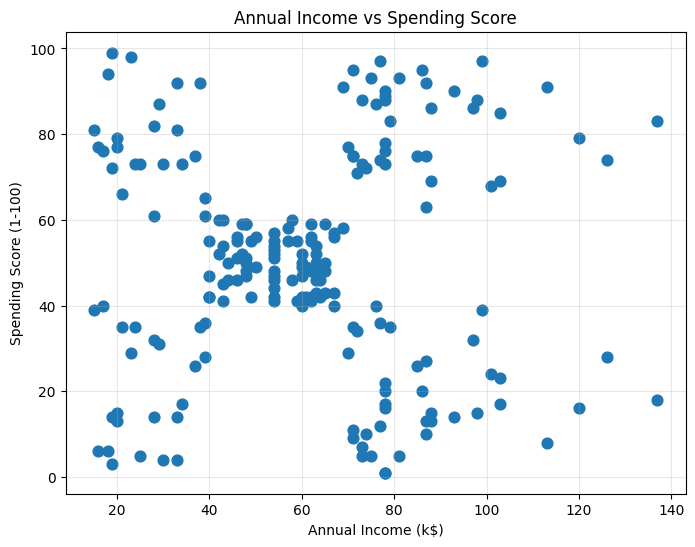

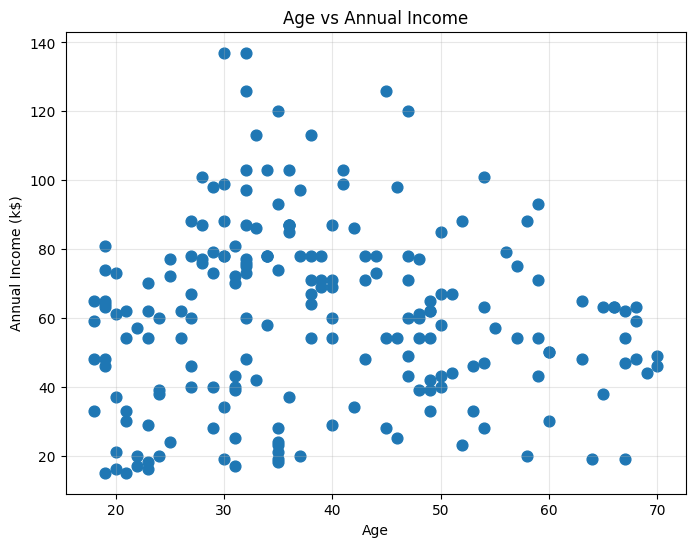

In [7]:
plt.figure(figsize=(8,6))
plt.scatter(df['Age'], df['Spending Score (1-100)'], s=60)
plt.xlabel('Age')
plt.ylabel('Spending Score (1-100)')
plt.title('Age vs Spending Score')
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(8,6))
plt.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'], s=60)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Annual Income vs Spending Score')
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(8,6))
plt.scatter(df['Age'], df['Annual Income (k$)'], s=60)
plt.xlabel('Age')
plt.ylabel('Annual Income (k$)')
plt.title('Age vs Annual Income')
plt.grid(alpha=0.3)
plt.show()

,count
Gender,
Female,112
Male,88


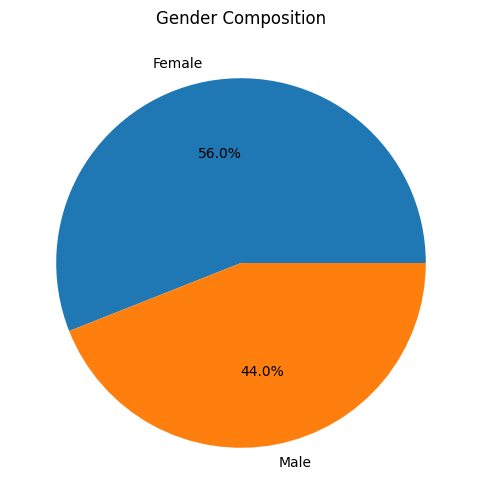

In [8]:
gender_counts = df['Gender'].value_counts()
display(gender_counts.to_frame('count'))

plt.figure(figsize=(6,6))
plt.pie(gender_counts.values, labels=gender_counts.index, autopct='%1.1f%%')
plt.title('Gender Composition')
plt.show()

## 4. Standardize variables for modeling

In [9]:
features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
X = df[features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

scaled_df = pd.DataFrame(X_scaled, columns=[f'{c}_scaled' for c in features])
scaled_df.head()

,Age_scaled,Annual Income (k$)_scaled,Spending Score (1-100)_scaled
0,-1.424569,-1.738999,-0.434801
1,-1.281035,-1.738999,1.195704
2,-1.352802,-1.700830,-1.715913
3,-1.137502,-1.700830,1.040418
4,-0.563369,-1.662660,-0.395980


## Helper functions

In [10]:
def cluster_profile_table(dataframe, label_col, features):
    return dataframe.groupby(label_col)[features].agg(['mean', 'std', 'median', 'min', 'max', 'count'])

def chi_square_gender_test(dataframe, label_col):
    table = pd.crosstab(dataframe['Gender'], dataframe[label_col])
    chi2, p_value, dof, expected = chi2_contingency(table)
    return table, chi2, p_value, dof

def reorder_groups_by_income_spending(dataframe, raw_label_col, new_group_col):
    summary = dataframe.groupby(raw_label_col)[['Annual Income (k$)', 'Spending Score (1-100)']].mean().sort_values(
        ['Annual Income (k$)', 'Spending Score (1-100)']
    )
    ordered_labels = list(summary.index)
    mapping = {old: i for i, old in enumerate(ordered_labels)}
    dataframe[new_group_col] = dataframe[raw_label_col].map(mapping).map(lambda x: f'Group {x+1}')
    return dataframe, mapping

def stability_summary(label_list, metric_values):
    ari_values = []
    base_labels = label_list[0]
    for i in range(1, len(label_list)):
        ari_values.append(adjusted_rand_score(base_labels, label_list[i]))
    return {
        'metric_mean': np.mean(metric_values),
        'metric_sd': np.std(metric_values, ddof=1) if len(metric_values) > 1 else 0.0,
        'ari_mean': np.mean(ari_values) if len(ari_values) > 0 else np.nan,
        'ari_min': np.min(ari_values) if len(ari_values) > 0 else np.nan,
        'ari_max': np.max(ari_values) if len(ari_values) > 0 else np.nan
    }

# 5. K-means analysis

This section discusses K-means as a standalone model.

### 5.1 K-means tuning

In [11]:
kmeans_rows = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=20,
        max_iter=300,
        tol=1e-4,
        random_state=111
    )
    labels = model.fit_predict(X_scaled)
    kmeans_rows.append({
        'k': k,
        'inertia': model.inertia_,
        'silhouette_score': silhouette_score(X_scaled, labels)
    })

kmeans_tuning = pd.DataFrame(kmeans_rows)
display(kmeans_tuning)

best_k_kmeans = int(kmeans_tuning.loc[kmeans_tuning['silhouette_score'].idxmax(), 'k'])
print('Best k for K-means =', best_k_kmeans)

,k,inertia,silhouette_score
0,2,389.386189,0.335472
1,3,295.212246,0.357793
2,4,205.225147,0.403958
3,5,168.247580,0.416643
4,6,133.868334,0.427428
5,7,117.011555,0.417232
6,8,103.788203,0.410089
7,9,92.154284,0.418091
8,10,81.929114,0.397816


Best k for K-means = 6


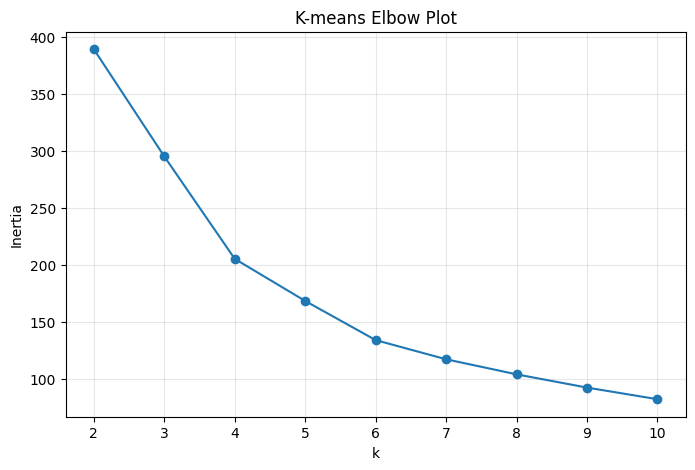

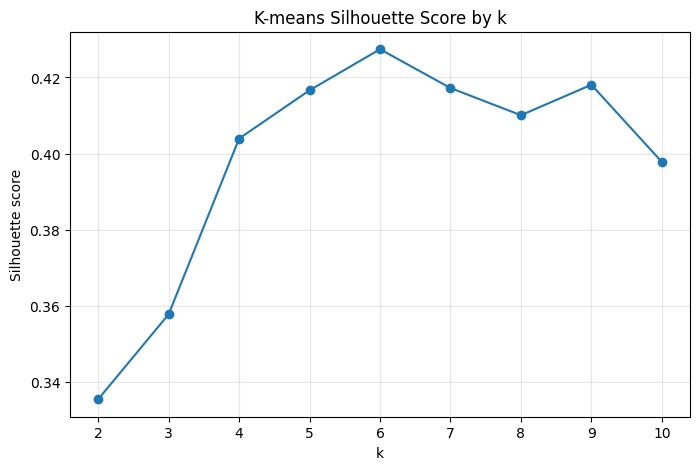

In [12]:
plt.figure(figsize=(8,5))
plt.plot(kmeans_tuning['k'], kmeans_tuning['inertia'], marker='o')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('K-means Elbow Plot')
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(8,5))
plt.plot(kmeans_tuning['k'], kmeans_tuning['silhouette_score'], marker='o')
plt.xlabel('k')
plt.ylabel('Silhouette score')
plt.title('K-means Silhouette Score by k')
plt.grid(alpha=0.3)
plt.show()

### 5.2 Final K-means model

In [13]:
kmeans_model = KMeans(
    n_clusters=best_k_kmeans,
    init='k-means++',
    n_init=20,
    max_iter=300,
    tol=1e-4,
    random_state=111
)
df['kmeans_cluster_raw'] = kmeans_model.fit_predict(X_scaled)
df, _ = reorder_groups_by_income_spending(df, 'kmeans_cluster_raw', 'kmeans_group')

print('K-means final summary')
print('Selected k:', best_k_kmeans)
print('Inertia:', round(kmeans_model.inertia_, 4))
print('Silhouette score:', round(silhouette_score(X_scaled, df['kmeans_cluster_raw']), 4))

display(df['kmeans_group'].value_counts().sort_index().rename('count').to_frame())
display(cluster_profile_table(df, 'kmeans_group', features))

K-means final summary
Selected k: 6
Inertia: 133.8683
Silhouette score: 0.4274


,count
kmeans_group,
Group 1,24
Group 2,21
Group 3,45
Group 4,38
Group 5,39
Group 6,33


Age                                 Annual Income (k$)                                  Spending Score (1-100)                                
                   mean        std median min max count               mean        std median min  max count                   mean        std median min max count
kmeans_group                                                                                                                                                      
Group 1       25.250000   5.326309   23.5  18  35    24          25.833333   8.057762   24.5  15   39    24              76.916667  13.416138   76.5  39  99    24
Group 2       45.523810  11.766984   46.0  20  67    21          26.285714   7.437357   25.0  16   39    21              19.380952  12.555780   15.0   3  40    21
Group 3       56.333333   8.453079   54.0  43  70    45          54.266667   8.975725   54.0  38   79    45              49.066667   6.300794   49.0  35  60    45
Group 4       26.684211   7.117186   26.0  18  40    38          57.578947   9.846474   60.0  40   76    38              47.789474   9.869850   49.5  10  60    38
Group 5       32.692308   3.728650   32.0  27  40    39          86.538462  16.312485   79.0  69  137    39              82.128205   9.364489   83.0  63  97    39
Group 6       41.939394  10.179450   43.0  19  59    33          88.939394  16.586778   86.0  71  137    33              16.969697   9.960813   16.0   1  39    33

In [14]:
kmeans_centers_original = pd.DataFrame(
    scaler.inverse_transform(kmeans_model.cluster_centers_),
    columns=features
)
display(kmeans_centers_original)

,Age,Annual Income (k$),Spending Score (1-100)
0,45.523810,26.285714,19.380952
1,56.333333,54.266667,49.066667
2,26.684211,57.578947,47.789474
3,25.250000,25.833333,76.916667
4,41.939394,88.939394,16.969697
5,32.692308,86.538462,82.128205


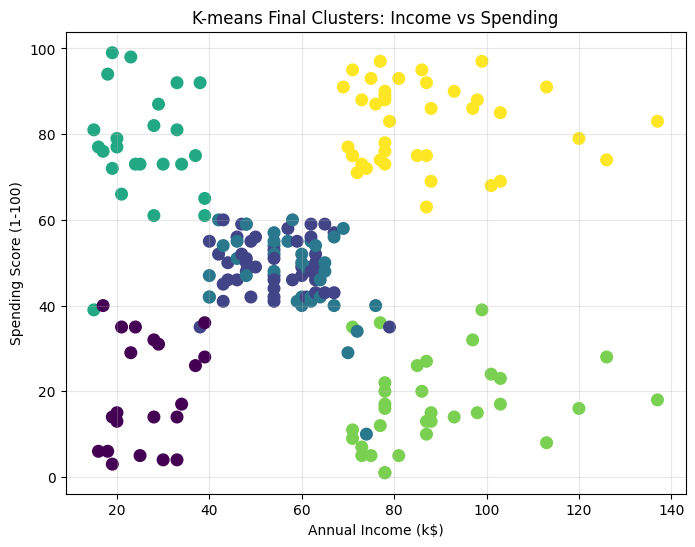

In [15]:
plt.figure(figsize=(8,6))
plt.scatter(
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    c=df['kmeans_cluster_raw'],
    s=70
)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('K-means Final Clusters: Income vs Spending')
plt.grid(alpha=0.3)
plt.show()

### 5.3 External test and validation for K-means

In [44]:
k_table, k_chi2, k_p, k_dof = chi_square_gender_test(df, 'kmeans_group')
print('K-means gender chi-square test')
print('Chi-square statistic =', round(k_chi2, 4))
print('Degrees of freedom   =', k_dof)
print('P-value              =', round(k_p, 6))
display(k_table)

K-means gender chi-square test
Chi-square statistic = 3.7398
Degrees of freedom   = 5
P-value              = 0.587451


kmeans_group,Group 1,Group 2,Group 3,Group 4,Group 5,Group 6
Gender,,,,,,
Female,14,13,26,24,21,14
Male,10,8,19,14,18,19


In [52]:
kmeans_labels = []
kmeans_sil_values = []

for seed in range(30):
    model = KMeans(
        n_clusters=best_k_kmeans,
        init='k-means++',
        n_init=20,
        max_iter=300,
        tol=1e-4,
        random_state=seed
    )
    labels = model.fit_predict(X_scaled)
    kmeans_labels.append(labels)
    kmeans_sil_values.append(silhouette_score(X_scaled, labels))

kmeans_stability = stability_summary(kmeans_labels, kmeans_sil_values)
display(pd.DataFrame([kmeans_stability]))

,metric_mean,metric_sd,ari_mean,ari_min,ari_max
0,0.42764,0.000448,0.996636,0.977224,1.0


### 5.4 Ablation experiment

Kmeans VS PCA+Kmeans

Original Silhouette Score: 0.4274
After-PCA Silhouette Score: 0.3775


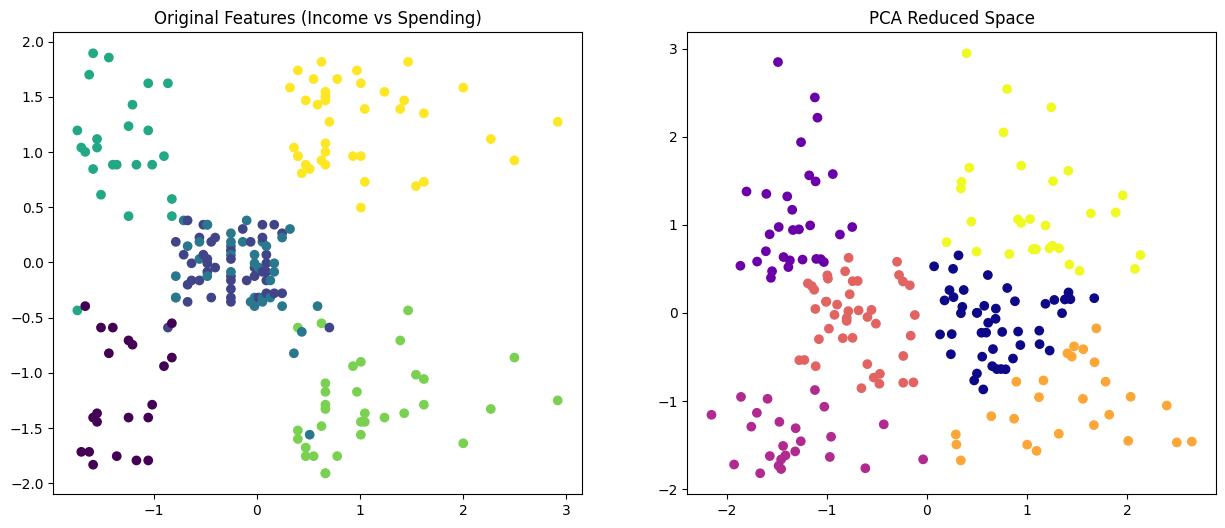

In [17]:
from sklearn.decomposition import PCA

#PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

#PCA + KMeans
pca_kmeans_model = KMeans(
    n_clusters=best_k_kmeans,
    init='k-means++',
    n_init=20,
    random_state=111
)
pca_labels = pca_kmeans_model.fit_predict(X_pca)

#Results comparison
print(f"Original Silhouette Score: {round(silhouette_score(X_scaled, df['kmeans_cluster_raw']), 4)}")
print(f"After-PCA Silhouette Score: {round(silhouette_score(X_pca, pca_labels), 4)}")

#Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
ax1.scatter(X_scaled[:, 1], X_scaled[:, 2], c=df['kmeans_cluster_raw'], cmap='viridis')
ax1.set_title('Original Features (Income vs Spending)')
ax2.scatter(X_pca[:, 0], X_pca[:, 1], c=pca_labels, cmap='plasma')
ax2.set_title('PCA Reduced Space')
plt.show()

### 5.4 Ablation experiment

Initialization(k-means++ vs Random)

initialization experiment is running (n_init=1)...


,metric_mean,metric_sd,ari_mean,ari_min,ari_max,Avg Iterations,Avg Inertia
Strategy,,,,,,,
k-means++,0.414235,0.022391,0.672355,0.481880,1.0,7.72,140.554468
random,0.401950,0.029139,0.826847,0.507459,1.0,8.88,146.383413


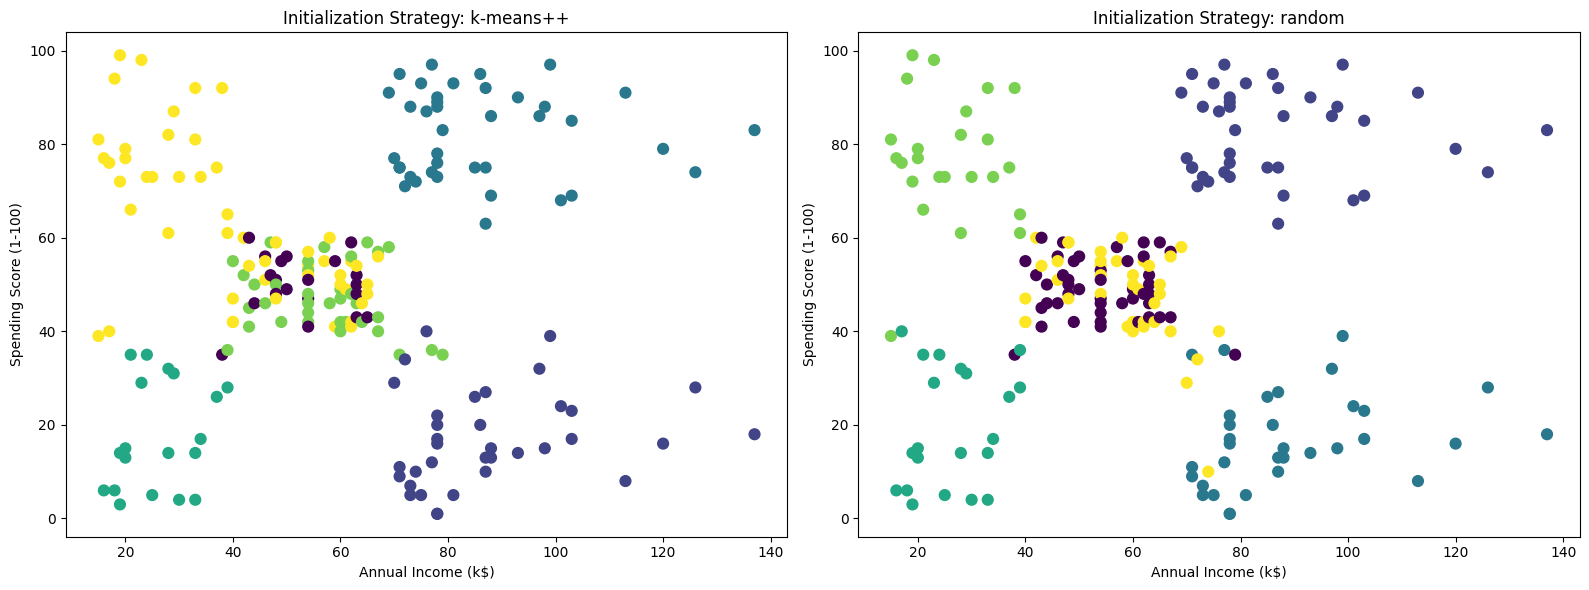

In [18]:
init_strategies = ['k-means++', 'random']
init_results = []
all_init_labels = {}

print("initialization experiment is running (n_init=1)...")

for strategy in init_strategies:
    temp_labels_list = []
    temp_sil_values = []
    iterations_list = []
    inertia_list = []

    for seed in range(50):
        test_model = KMeans(
            n_clusters=best_k_kmeans,
            init=strategy,
            n_init=1,
            max_iter=300,
            random_state=seed
        )
        labels = test_model.fit_predict(X_scaled)

        temp_labels_list.append(labels)
        temp_sil_values.append(silhouette_score(X_scaled, labels))
        iterations_list.append(test_model.n_iter_)
        inertia_list.append(test_model.inertia_)


    stability = stability_summary(temp_labels_list, temp_sil_values)
    stability['Strategy'] = strategy
    stability['Avg Iterations'] = np.mean(iterations_list)
    stability['Avg Inertia'] = np.mean(inertia_list)

    init_results.append(stability)
    all_init_labels[strategy] = temp_labels_list[0]


init_comparison_df = pd.DataFrame(init_results).set_index('Strategy')
display(init_comparison_df)

#Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for i, strategy in enumerate(init_strategies):
    ax = axes[i]
    scatter = ax.scatter(
        df['Annual Income (k$)'],
        df['Spending Score (1-100)'],
        c=all_init_labels[strategy],
        cmap='viridis', s=60
    )
    ax.set_title(f'Initialization Strategy: {strategy}')
    ax.set_xlabel('Annual Income (k$)')
    ax.set_ylabel('Spending Score (1-100)')

plt.tight_layout()
plt.show()

# 6. GMM analysis

This section discusses Gaussian Mixture Models separately.

### 6.1 GMM tuning

In [27]:
gmm_rows = []

for k in range(2, 11):
    model = GaussianMixture(
        n_components=k,
        covariance_type='full',
        random_state=111,
        n_init=10
    )
    model.fit(X_scaled)
    labels = model.predict(X_scaled)
    gmm_rows.append({
        'k': k,
        'BIC': model.bic(X_scaled),
        'AIC': model.aic(X_scaled),
        'silhouette_score': silhouette_score(X_scaled, labels)
    })

gmm_tuning = pd.DataFrame(gmm_rows)
display(gmm_tuning)

best_k_gmm = int(gmm_tuning.loc[gmm_tuning['BIC'].idxmin(), 'k'])
print('Best number of components for GMM by BIC =', best_k_gmm)

,k,BIC,AIC,silhouette_score
0,2,1656.962213,1594.294183,0.328788
1,3,1623.824883,1528.173679,0.340558
2,4,1596.999117,1468.364740,0.373447
3,5,1576.707936,1415.090385,0.406367
4,6,1599.229239,1404.628514,0.376684
5,7,1621.622622,1394.038724,0.389701
6,8,1649.655218,1389.088146,0.393814
7,9,1673.751039,1380.200794,0.351310
8,10,1702.049263,1375.515844,0.340630


Best number of components for GMM by BIC = 5


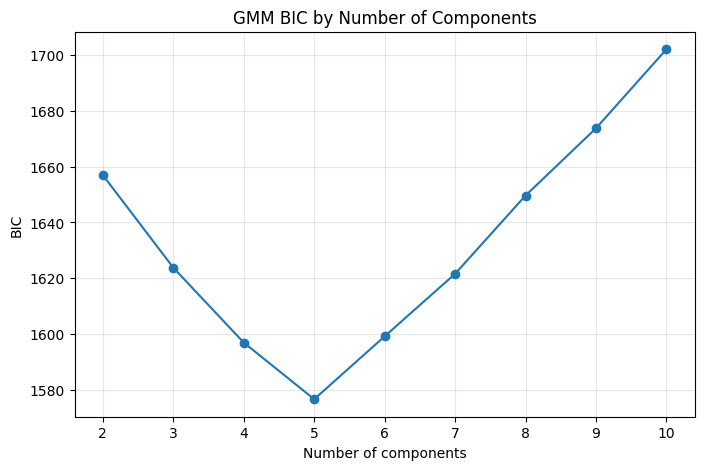

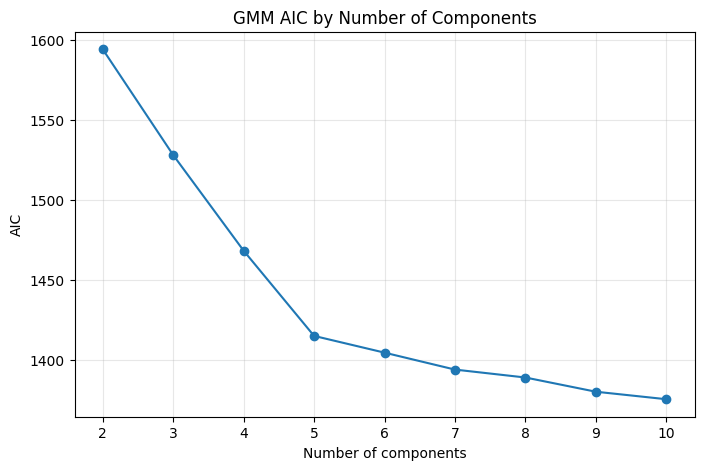

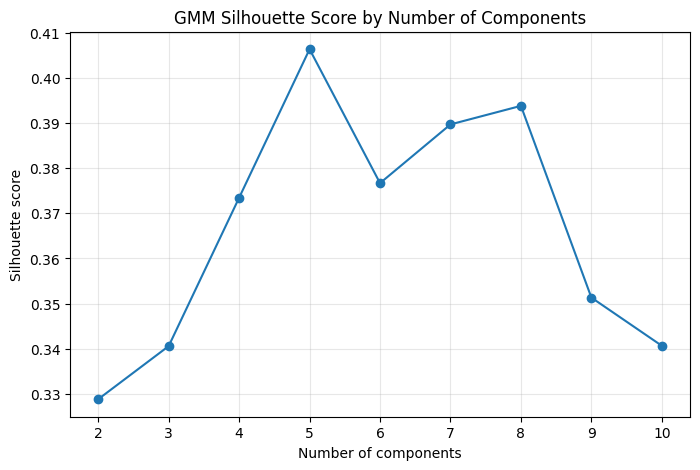

In [28]:
plt.figure(figsize=(8,5))
plt.plot(gmm_tuning['k'], gmm_tuning['BIC'], marker='o')
plt.xlabel('Number of components')
plt.ylabel('BIC')
plt.title('GMM BIC by Number of Components')
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(8,5))
plt.plot(gmm_tuning['k'], gmm_tuning['AIC'], marker='o')
plt.xlabel('Number of components')
plt.ylabel('AIC')
plt.title('GMM AIC by Number of Components')
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(8,5))
plt.plot(gmm_tuning['k'], gmm_tuning['silhouette_score'], marker='o')
plt.xlabel('Number of components')
plt.ylabel('Silhouette score')
plt.title('GMM Silhouette Score by Number of Components')
plt.grid(alpha=0.3)
plt.show()

### 6.2 Final GMM model

In [29]:
gmm_model = GaussianMixture(
    n_components=best_k_gmm,
    covariance_type='full',
    random_state=111,
    n_init=10
)
gmm_model.fit(X_scaled)
df['gmm_cluster_raw'] = gmm_model.predict(X_scaled)
df, _ = reorder_groups_by_income_spending(df, 'gmm_cluster_raw', 'gmm_group')

gmm_prob = gmm_model.predict_proba(X_scaled)
df['gmm_max_prob'] = gmm_prob.max(axis=1)

print('GMM final summary')
print('Selected components:', best_k_gmm)
print('BIC:', round(gmm_model.bic(X_scaled), 4))
print('AIC:', round(gmm_model.aic(X_scaled), 4))
print('Average log-likelihood:', round(gmm_model.score(X_scaled), 4))
print('Silhouette score:', round(silhouette_score(X_scaled, df['gmm_cluster_raw']), 4))
print('Average max posterior probability:', round(df['gmm_max_prob'].mean(), 4))

display(df['gmm_group'].value_counts().sort_index().rename('count').to_frame())
display(cluster_profile_table(df, 'gmm_group', features))

GMM final summary
Selected components: 5
BIC: 1576.7079
AIC: 1415.0904
Average log-likelihood: -3.2927
Silhouette score: 0.4064
Average max posterior probability: 0.9739


,count
gmm_group,
Group 1,23
Group 2,53
Group 3,51
Group 4,39
Group 5,34


Age                                 Annual Income (k$)                                  Spending Score (1-100)                                
                mean        std median min max count               mean        std median min  max count                   mean        std median min max count
gmm_group                                                                                                                                                      
Group 1    45.217391  13.228607   46.0  19  67    23          26.304348   7.893811   25.0  15   39    23              20.913043  13.017167   17.0   3  40    23
Group 2    24.830189   5.060161   24.0  18  35    53          43.226415  17.524314   42.0  15   76    53              62.037736  17.262634   59.0  29  99    53
Group 3    53.392157  10.204075   50.0  32  70    51          55.372549   8.277586   54.0  40   71    51              48.980392   6.211248   48.0  35  60    51
Group 4    32.692308   3.728650   32.0  27  40    39          86.538462  16.312485   79.0  69  137    39              82.128205   9.364489   83.0  63  97    39
Group 5    41.647059  11.058748   42.5  19  59    34          88.735294  16.332360   85.5  71  137    34              16.764706   9.881292   15.5   1  39    34

In [30]:
gmm_means_original = pd.DataFrame(
    scaler.inverse_transform(gmm_model.means_),
    columns=features
)
display(gmm_means_original)

display(pd.DataFrame({'component': range(best_k_gmm), 'mixing_weight': gmm_model.weights_}))

,Age,Annual Income (k$),Spending Score (1-100)
0,41.820299,88.922197,16.705641
1,44.837230,26.656913,21.617473
2,24.637980,43.304840,61.922224
3,52.814841,55.447547,48.937658
4,32.702661,86.276966,81.943839


,component,mixing_weight
0,0,0.166042
1,1,0.117777
2,2,0.257030
3,3,0.262384
4,4,0.196766


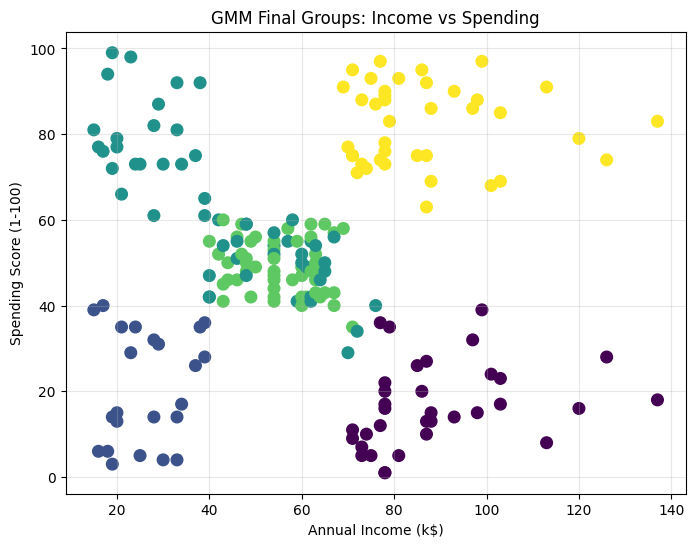

In [31]:
plt.figure(figsize=(8,6))
plt.scatter(
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    c=df['gmm_cluster_raw'],
    s=70
)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('GMM Final Groups: Income vs Spending')
plt.grid(alpha=0.3)
plt.show()

### 6.3 External test and validation for GMM

In [32]:
g_table, g_chi2, g_p, g_dof = chi_square_gender_test(df, 'gmm_group')
print('GMM gender chi-square test')
print('Chi-square statistic =', round(g_chi2, 4))
print('Degrees of freedom   =', g_dof)
print('P-value              =', round(g_p, 6))
display(g_table)

GMM gender chi-square test
Chi-square statistic = 3.1025
Degrees of freedom   = 4
P-value              = 0.540829


gmm_group,Group 1,Group 2,Group 3,Group 4,Group 5
Gender,,,,,
Female,14,33,29,21,15
Male,9,20,22,18,19


In [33]:
gmm_labels = []
gmm_sil_values = []
gmm_bic_values = []

for seed in range(30):
    model = GaussianMixture(
        n_components=best_k_gmm,
        covariance_type='full',
        random_state=seed,
        n_init=10
    )
    model.fit(X_scaled)
    labels = model.predict(X_scaled)
    gmm_labels.append(labels)
    gmm_sil_values.append(silhouette_score(X_scaled, labels))
    gmm_bic_values.append(model.bic(X_scaled))

gmm_stability = stability_summary(gmm_labels, gmm_sil_values)
gmm_stability['bic_mean'] = np.mean(gmm_bic_values)
gmm_stability['bic_sd'] = np.std(gmm_bic_values, ddof=1)
display(pd.DataFrame([gmm_stability]))

,metric_mean,metric_sd,ari_mean,ari_min,ari_max,bic_mean,bic_sd
0,0.406367,1.693804e-16,1.0,1.0,1.0,1576.707936,1.034229e-13


# 7. Spectral Clustering analysis

This section discusses Spectral Clustering separately.

### 7.1 Spectral Clustering tuning

In [34]:
spectral_rows = []

for k in range(2, 11):
    model = SpectralClustering(
        n_clusters=k,
        affinity='nearest_neighbors',
        n_neighbors=10,
        assign_labels='kmeans',
        random_state=111
    )
    labels = model.fit_predict(X_scaled)
    spectral_rows.append({
        'k': k,
        'silhouette_score': silhouette_score(X_scaled, labels)
    })

spectral_tuning = pd.DataFrame(spectral_rows)
display(spectral_tuning)

best_k_spectral = int(spectral_tuning.loc[spectral_tuning['silhouette_score'].idxmax(), 'k'])
print('Best k for Spectral Clustering =', best_k_spectral)

,k,silhouette_score
0,2,0.249192
1,3,0.349623
2,4,0.397809
3,5,0.373406
4,6,0.414537
5,7,0.414818
6,8,0.377654
7,9,0.379641
8,10,0.371448


Best k for Spectral Clustering = 7


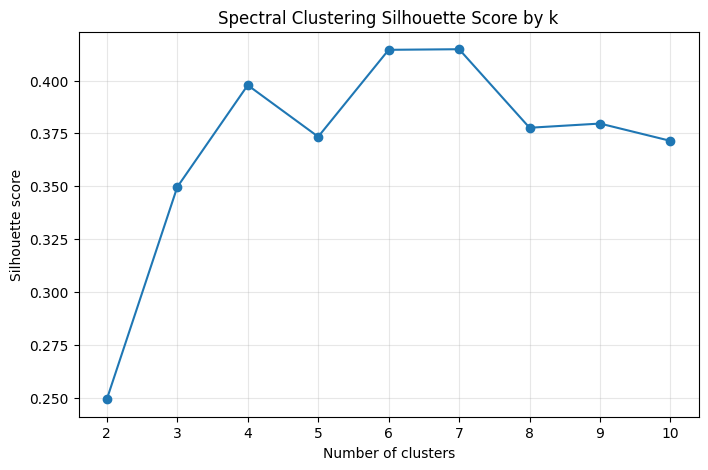

In [35]:
plt.figure(figsize=(8,5))
plt.plot(spectral_tuning['k'], spectral_tuning['silhouette_score'], marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette score')
plt.title('Spectral Clustering Silhouette Score by k')
plt.grid(alpha=0.3)
plt.show()

### 7.2 Final Spectral Clustering model

In [36]:
spectral_model = SpectralClustering(
    n_clusters=best_k_spectral,
    affinity='nearest_neighbors',
    n_neighbors=10,
    assign_labels='kmeans',
    random_state=111
)
df['spectral_cluster_raw'] = spectral_model.fit_predict(X_scaled)
df, _ = reorder_groups_by_income_spending(df, 'spectral_cluster_raw', 'spectral_group')

print('Spectral Clustering final summary')
print('Selected k:', best_k_spectral)
print('Silhouette score:', round(silhouette_score(X_scaled, df['spectral_cluster_raw']), 4))

display(df['spectral_group'].value_counts().sort_index().rename('count').to_frame())
display(cluster_profile_table(df, 'spectral_group', features))

Spectral Clustering final summary
Selected k: 7
Silhouette score: 0.4148


,count
spectral_group,
Group 1,21
Group 2,21
Group 3,19
Group 4,33
Group 5,34
Group 6,39
Group 7,33


Age                                 Annual Income (k$)                                  Spending Score (1-100)                                
                     mean        std median min max count               mean        std median min  max count                   mean        std median min max count
spectral_group                                                                                                                                                      
Group 1         25.333333   5.378971   23.0  18  35    21          25.095238   7.133756   24.0  15   38    21              80.047619  10.249274   77.0  61  99    21
Group 2         44.142857  13.089254   45.0  19  67    21          25.142857   7.226934   24.0  15   39    21              19.523810  12.769569   15.0   3  40    21
Group 3         65.263158   3.618503   66.0  59  70    19          53.105263   8.292532   50.0  38   65    19              49.789474   6.451347   50.0  35  60    19
Group 4         24.727273   4.995452   24.0  18  34    33          55.272727  10.518652   58.0  39   76    33              49.969697   8.251836   51.0  29  65    33
Group 5         47.411765   4.961168   48.0  38  57    34          56.147059   9.670738   55.5  39   77    34              47.558824   6.924665   46.5  35  59    34
Group 6         32.692308   3.728650   32.0  27  40    39          86.538462  16.312485   79.0  69  137    39              82.128205   9.364489   83.0  63  97    39
Group 7         41.454545  11.172206   42.0  19  59    33          89.090909  16.451375   86.0  71  137    33              16.181818   9.422230   15.0   1  39    33

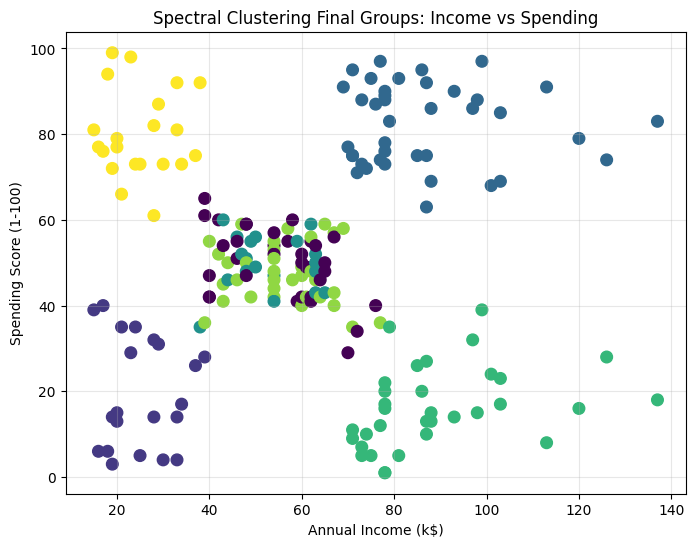

In [37]:
plt.figure(figsize=(8,6))
plt.scatter(
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    c=df['spectral_cluster_raw'],
    s=70
)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Spectral Clustering Final Groups: Income vs Spending')
plt.grid(alpha=0.3)
plt.show()

### 7.3 External test and validation for Spectral Clustering

In [38]:
s_table, s_chi2, s_p, s_dof = chi_square_gender_test(df, 'spectral_group')
print('Spectral Clustering gender chi-square test')
print('Chi-square statistic =', round(s_chi2, 4))
print('Degrees of freedom   =', s_dof)
print('P-value              =', round(s_p, 6))
display(s_table)

Spectral Clustering gender chi-square test
Chi-square statistic = 5.3422
Degrees of freedom   = 6
P-value              = 0.500733


spectral_group,Group 1,Group 2,Group 3,Group 4,Group 5,Group 6,Group 7
Gender,,,,,,,
Female,12,13,8,22,21,21,15
Male,9,8,11,11,13,18,18


In [39]:
spectral_labels = []
spectral_sil_values = []

for seed in range(30):
    model = SpectralClustering(
        n_clusters=best_k_spectral,
        affinity='nearest_neighbors',
        n_neighbors=10,
        assign_labels='kmeans',
        random_state=seed
    )
    labels = model.fit_predict(X_scaled)
    spectral_labels.append(labels)
    spectral_sil_values.append(silhouette_score(X_scaled, labels))

spectral_stability = stability_summary(spectral_labels, spectral_sil_values)
display(pd.DataFrame([spectral_stability]))

,metric_mean,metric_sd,ari_mean,ari_min,ari_max
0,0.414818,5.646013e-17,1.0,1.0,1.0


# 8.Hierarchical Cluster

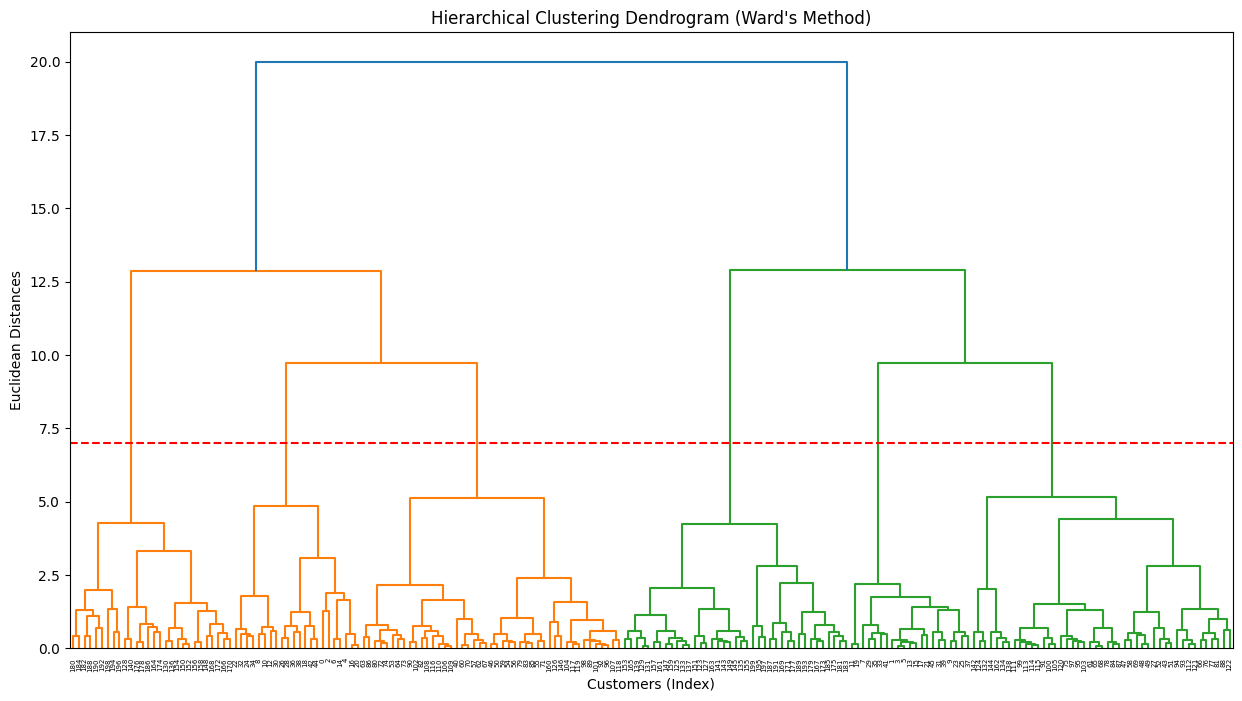

In [48]:
import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering

#Dendrogram
plt.figure(figsize=(15, 8))
#Ward
linkage_matrix = sch.linkage(X_scaled, method='ward')
dendrogram = sch.dendrogram(linkage_matrix)

plt.title('Hierarchical Clustering Dendrogram (Ward\'s Method)')
plt.xlabel('Customers (Index)')
plt.ylabel('Euclidean Distances')
plt.axhline(y=7, color='r', linestyle='--')
plt.show()

### 8.1 Hierarchical Clustering tuning

k=2, Silhouette Score: 0.318
k=3, Silhouette Score: 0.3215
k=4, Silhouette Score: 0.3615
k=5, Silhouette Score: 0.39
k=6, Silhouette Score: 0.4201
k=7, Silhouette Score: 0.3983
k=8, Silhouette Score: 0.3665
k=9, Silhouette Score: 0.3754
k=10, Silhouette Score: 0.3809


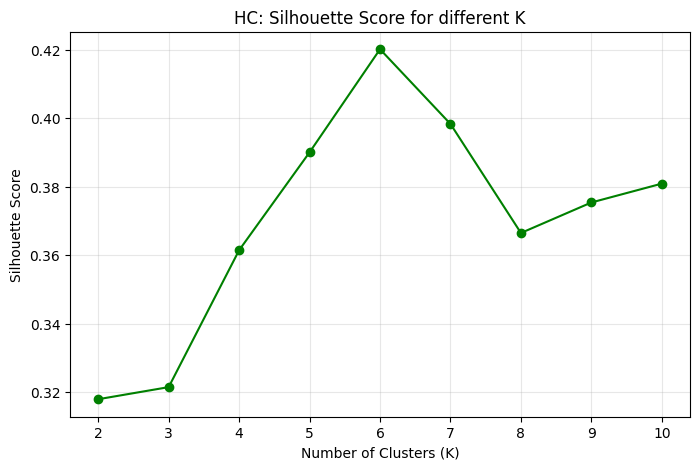

The best K based on math is: 6


In [49]:
#Find best K for Hierarchical Clustering
hc_scores = []
k_range = range(2, 11)

for k in k_range:
    # Use the same settings as your HC model
    model = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward')
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    hc_scores.append(score)
    print(f"k={k}, Silhouette Score: {round(score, 4)}")

# Plot the scores
plt.figure(figsize=(8, 5))
plt.plot(k_range, hc_scores, marker='o', color='green')
plt.title('HC: Silhouette Score for different K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.grid(True, alpha=0.3)
plt.show()

# Find the winner
best_hc_k = k_range[np.argmax(hc_scores)]
print(f"The best K based on math is: {best_hc_k}")

### 8.2 Final Spectral Clustering model

Hierarchical Clustering final summary
Silhouette score: 0.4201


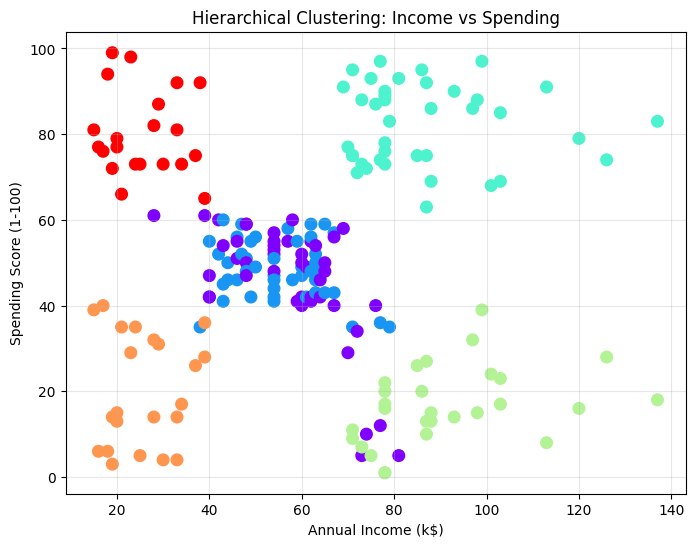

In [50]:
n_clusters_hc = 6
hc_model = AgglomerativeClustering(
    n_clusters=n_clusters_hc,
    metric='euclidean',
    linkage='ward'
)
df['hc_cluster_raw'] = hc_model.fit_predict(X_scaled)


df, _ = reorder_groups_by_income_spending(df, 'hc_cluster_raw', 'hc_group')

print('Hierarchical Clustering final summary')
print('Silhouette score:', round(silhouette_score(X_scaled, df['hc_cluster_raw']), 4))

#Visualization
plt.figure(figsize=(8,6))
plt.scatter(
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    c=df['hc_cluster_raw'],
    cmap='rainbow',
    s=70
)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Hierarchical Clustering: Income vs Spending')
plt.grid(alpha=0.3)
plt.show()

### 8.3 External Validation: Gender Test for HC

Question: "Is there a relationship between Gender and HC Groups?"

In [41]:
#Run the Chi-square
h_table, h_chi2, h_p, h_dof = chi_square_gender_test(df, 'hc_group')

print('--- Hierarchical Clustering: Gender Test ---')
print('Chi-square statistic =', round(h_chi2, 4))
print('P-value              =', round(h_p, 6))

#Show the table (Count of Men and Women in each group)
display(h_table)

#Simple Conclusion
if h_p < 0.05:
    print("Conclusion: Gender matters! The groups have different male/female mix.")
else:
    print("Conclusion: Gender does not matter much for these groups.")

--- Hierarchical Clustering: Gender Test ---
Chi-square statistic = 1.2871
P-value              = 0.936258


hc_group,Group 1,Group 2,Group 3,Group 4,Group 5,Group 6
Gender,,,,,,
Female,13,13,24,27,21,14
Male,8,9,21,18,18,14


Conclusion: Gender does not matter much for these groups.


# 9. Final model comparison

--- Running Final Comparison (All Models set to k=6) ---
K-Means at k=6, Silhouette Score: 0.4274
HC at k=6, Silhouette Score: 0.4201
GMM at k=6, Silhouette Score: 0.3767
Spectral at k=6, Silhouette Score: 0.4145


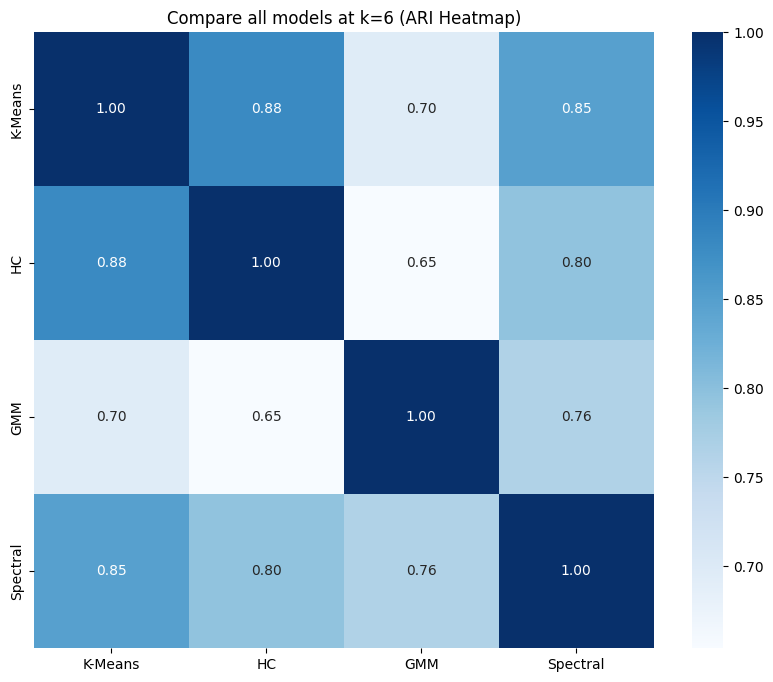

,Model,Silhouette at k=6
0,K-Means,0.427428
1,HC,0.420117
2,GMM,0.376684
3,Spectral,0.414537


In [46]:
#Model Comparison (All set to k=6)

print("--- Running Final Comparison (All Models set to k=6) ---")

#Define all models with k=6
models_comp = {
    'K-Means': KMeans(n_clusters=6, init='k-means++', n_init=20, random_state=111),

    'HC': AgglomerativeClustering(n_clusters=6, metric='euclidean', linkage='ward'),

    'GMM': GaussianMixture(n_components=6, covariance_type='full', n_init=10, random_state=111),

    'Spectral': SpectralClustering(n_clusters=6, affinity='nearest_neighbors', n_neighbors=10, random_state=111)
}

#Fit models and save labels
comp_labels = {}
comp_sil_scores = []

for name, model in models_comp.items():
    if name == 'GMM':
        model.fit(X_scaled)
        labels = model.predict(X_scaled)
    else:
        labels = model.fit_predict(X_scaled)

    comp_labels[name] = labels

    # Calculate silhouette score for this model at k=6
    score = silhouette_score(X_scaled, labels)
    comp_sil_scores.append(score)
    print(f"{name} at k=6, Silhouette Score: {round(score, 4)}")

#Create ARI Heatmap
from sklearn.metrics import adjusted_rand_score
import seaborn as sns

names = list(models_comp.keys())
ari_matrix = np.zeros((len(names), len(names)))

for i in range(len(names)):
    for j in range(len(names)):
        ari_matrix[i, j] = adjusted_rand_score(comp_labels[names[i]], comp_labels[names[j]])

ari_df = pd.DataFrame(ari_matrix, index=names, columns=names)

plt.figure(figsize=(10, 8))
sns.heatmap(ari_df, annot=True, cmap='Blues', fmt='.2f')
plt.title('Compare all models at k=6 (ARI Heatmap)')
plt.show()

#Final Table
summary_df = pd.DataFrame({
    'Model': names,
    'Silhouette at k=6': comp_sil_scores
})
display(summary_df)

### Quality, Stability, Interpretability

--- Final Comparison Table (at k=6) ---


,Model,Quality (Silhouette),Stability (Mean),Stability (SD),Gender Link (P-Value)
0,K-Means,0.4274,0.4276,0.0004,0.5875
1,HC,0.4201,0.4201,0.0000,0.9363
2,GMM,0.3767,0.4064,0.0000,0.5408
3,Spectral,0.4145,0.4145,0.0000,0.5007


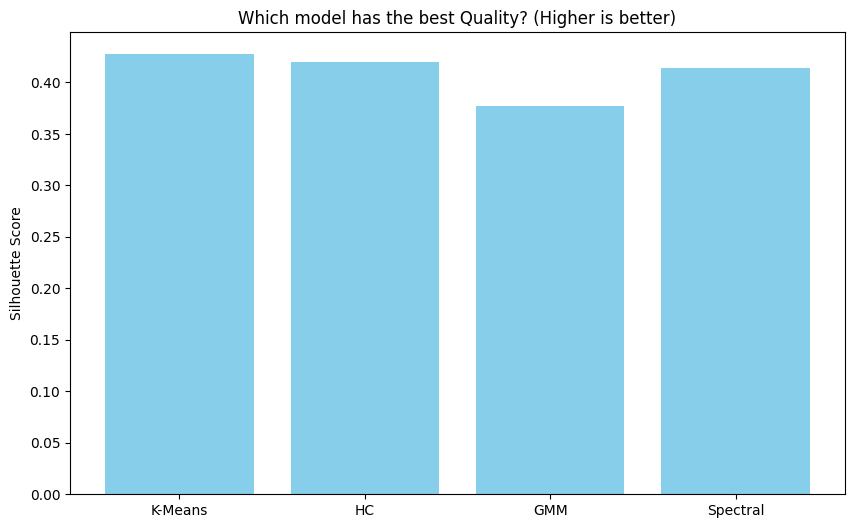

In [54]:
all_stability = {
    'K-Means': kmeans_stability,
    'GMM': gmm_stability,
    'HC': {'metric_mean': silhouette_score(X_scaled, comp_labels['HC']), 'metric_sd': 0.0},
    'Spectral': {'metric_mean': silhouette_score(X_scaled, comp_labels['Spectral']), 'metric_sd': 0.0}
}

p_values = {
    'K-Means': k_p,
    'HC': h_p,
    'GMM': g_p,
    'Spectral': s_p
}

final_comparison_rows = []

for name in ['K-Means', 'HC', 'GMM', 'Spectral']:
    current_sil = silhouette_score(X_scaled, comp_labels[name])

    final_comparison_rows.append({
        'Model': name,
        #Quality
        'Quality (Silhouette)': round(current_sil, 4),

        #Stability
        'Stability (Mean)': round(all_stability[name]['metric_mean'], 4),
        'Stability (SD)': round(all_stability[name].get('metric_sd', 0.0), 4),

        #Interpretability
        'Gender Link (P-Value)': round(p_values[name], 4)
    })

#Show the table
model_comparison_table = pd.DataFrame(final_comparison_rows)
print("--- Final Comparison Table (at k=6) ---")
display(model_comparison_table)

#Visualization
plt.figure(figsize=(10, 6))
plt.bar(model_comparison_table['Model'], model_comparison_table['Quality (Silhouette)'], color='skyblue')
plt.title('Which model has the best Quality? (Higher is better)')
plt.ylabel('Silhouette Score')
plt.show()

# 10. Export tables for the report

In [ ]:
with pd.ExcelWriter('Customer_Segmentation_Report.xlsx', engine='openpyxl') as writer:

    final_assignments = df[[
        'CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)',
        'kmeans_group', 'hc_group', 'gmm_group', 'spectral_group'
    ]].copy()
    final_assignments.to_excel(writer, sheet_name='Customer_Assignments', index=False)


    model_comparison_table.to_excel(writer, sheet_name='Model_Comparison', index=False)


    kmeans_tuning.to_excel(writer, sheet_name='Tuning_KMeans', index=False)
    gmm_tuning.to_excel(writer, sheet_name='Tuning_GMM', index=False)
    spectral_tuning.to_excel(writer, sheet_name='Tuning_Spectral', index=False)

    kmeans_profile = cluster_profile_table(df, 'kmeans_group', features)
    kmeans_profile.to_excel(writer, sheet_name='KMeans_Group_Profiles')

print('All tables saved to: Customer_Segmentation_Report.xlsx')